<center>

# Kappa Foundation | Initial Investment Policy Analysis

***BFIN WS2026 · Investments · Group Assignment***

**Group members:** Võ Hoàng Ngọc Phú (106240420) · Trần Bình Minh (106240415) · Hoàng Trọng Đăng (103240490)

Notebook 02 of 02 · Decision date 31 Dec 2022 · Initial decision record, 22 October 2026
</center>

---

### Our decision in one paragraph

* **Fixed payments first.** The 2024 and 2027 payments (USD 2.4M and 3.6M) are funded by **exact cash-flow matching with Beta (2y zero) and Delta (5y, 3.5%)**. We keep the Delta coupons of 2023–2024 as cash to complete the 2024 payment.
* **The rest has to grow.** Holding only safe bonds does not reach USD 8M in Dec-2022 money by 2030, so part of the remainder goes into a growth portfolio of **10 US stocks (6 sectors) + 2 US equity ETFs**, and the rest into **Epsilon**, which matures exactly in Dec 2030.
* **Growth portfolio = constrained Markowitz with a single-index (SIM) covariance and CAPM-based expected returns.** We compare it with the sample covariance and reject the unconstrained historical max-Sharpe portfolio ("Eta") because it piles into a few past winners.
* **Size of the equity part** = the smaller of the utility optimum ($A = 4$) and our two loss limits (1-year 95% VaR ≤ 10% and a stress loss ≤ 15% of the fund, both net of the fixed payments). Result: 49% of the remainder, about 26% of the fund.
* **Comparator:** SPY (buy-and-hold, total return). The evaluation rule for 2023–2025 is frozen in Section 7 and run only in the final submission.

### How to run

* *Run All* from top to bottom. Everything is read from `data/raw/` (saved by `01_data_retrieval.ipynb`), so no internet is needed.
* All assumptions sit in one cell (Section 0). Tables and figures are written to `outputs/original_22Oct/` with names `T##_...csv` / `F##_...png`; the frozen policy is `outputs/original_22Oct/frozen_policy.json`.
* To test a change, set a new `TAG` in Section 0 so the original outputs are not overwritten.

---

## 0. Setup and frozen assumptions

### 0.1 Packages, paths and all team assumptions

**What:** we load packages, locate the project folder and put every assumption into one dictionary `P`.

**Why:** if a number is used in two sections it must be the same number; keeping them together also makes the decision record easy to check. The sources behind each assumption are listed in `theory_and_sources/B_external_sources_and_assumptions.ipynb`.

| Assumption | Value | Where it comes from |
|:--|--:|:--|
| Inflation 2023–2030 | 2.3% p.a. (stress 3.5%) | Treasury 5y/10y breakeven on 30 Dec 2022 (≈2.3%); Fed 2% long-run goal |
| Equity risk premium (ERP) | 5.0% | Team choice; Damodaran data: historical 1928–2022 = 5.1% (geometric), implied Jan 2023 = 5.94% |
| Risk aversion $A$ | 4 (grid 2–8) | Team choice, middle of the usual 2–6 range (L04/L05) |
| Trustees' "~15% loss" | 1-yr 95% VaR ≤ 10% **and** stress loss ≤ 15% of the fund, net of the fixed payments | Our interpretation (Section 5.6) |
| Weight limits (growth sleeve) | stock 1–8%, ETF 1–35%, sector (stocks) ≤ 15% | Team choice: diversification and liquidity |
| Trading costs (one way) | stocks 10 bp, ETFs 3 bp, case bonds 0 (bought at quoted prices) | Team estimate |
| Cash reserve | USD 100,000 at 0% | Team choice: trading costs, coupon timing |
| Estimation window | Jan 2016 – Dec 2022 (84 months) | Section 1.4 |
| Evaluation | Jan 2023 – Dec 2025, rebalanced each December | Section 7 |

In [1]:
import json, hashlib, zipfile, math, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.optimize import brentq, minimize
from scipy.stats import norm
from IPython.display import display, Markdown, Math

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'README.md').exists() and (p / 'notebooks').exists())
RAW = ROOT / 'data' / 'raw'

P = dict(
    TAG='original_22Oct',
    FUND=12_000_000, LIAB={2024: 2_400_000, 2027: 3_600_000},
    GOAL_REAL=8_000_000, GOAL_YEAR=2030, START_YEAR=2022,
    INFL=0.023, INFL_STRESS=0.035,
    ERP=0.05, A=4, A_GRID=[2, 3, 4, 5, 6, 8],
    VAR_LIMIT=0.10, STRESS_LIMIT=0.15, EQ_STRESS=-0.40, Z95=1.645,
    W_MIN=0.01, W_STOCK_MAX=0.08, W_ETF_MAX=0.35, W_SECTOR_MAX=0.15,
    TC_STOCK=0.0010, TC_ETF=0.0003, CASH=100_000,
    EST_START='2016-01', EST_END='2022-12', EVAL_START='2023-01', EVAL_END='2025-12',
    DRIFT_BAND=0.03, BENCH='SPY', SEED=2022,
)
SECTOR = {'MSA': 'Industrials', 'KAI': 'Industrials', 'GEF': 'Materials', 'IOSP': 'Materials',
          'FLO': 'Consumer Staples', 'CALM': 'Consumer Staples', 'IDA': 'Utilities', 'NWN': 'Utilities',
          'CHE': 'Health Care', 'NSIT': 'Information Technology'}
NAME = {'MSA': 'MSA Safety', 'KAI': 'Kadant', 'GEF': 'Greif (Class A)', 'IOSP': 'Innospec', 'FLO': 'Flowers Foods',
        'CALM': 'Cal-Maine Foods', 'IDA': 'IDACORP', 'NWN': 'Northwest Natural Holding', 'CHE': 'Chemed',
        'NSIT': 'Insight Enterprises', 'XMLV': 'Invesco S&P MidCap Low Volatility ETF',
        'RWL': 'Invesco S&P 500 Revenue ETF', 'SPY': 'SPDR S&P 500 ETF Trust'}
STOCKS = list(SECTOR); ETFS = ['XMLV', 'RWL']; ASSETS = STOCKS + ETFS; BENCH = P['BENCH']
CUTOFF = pd.Timestamp('2022-12-31')

OUT = ROOT / 'outputs' / P['TAG']; OUT.mkdir(parents=True, exist_ok=True)
def save(df, name, index=True):
    df.to_csv(OUT / f'{name}.csv', index=index); return df
def savefig(fig, name):
    fig.savefig(OUT / f'{name}.png', bbox_inches='tight'); plt.show()
def pct(x, d=2): return f'{100 * x:.{d}f}%'
def usd(x): return f'USD {x:,.0f}'
print('Root:', ROOT, '| outputs ->', OUT.relative_to(ROOT))

Root: /data/kappa | outputs -> outputs/original_22Oct


**Output:** project root and output folder. Nothing is downloaded in this notebook.

---

## 1. Data: load, check and convert to monthly returns

### 1.1 Check that the raw files are the frozen ones

**What:** we recompute the SHA-256 hash of every raw file and compare it with `data/raw/source_record.csv`.

**Why:** the brief requires the analysis to be reproducible from saved data. If a file was changed or re-downloaded, the notebook stops here instead of giving different numbers silently.

In [2]:
record = pd.read_csv(RAW / 'source_record.csv')
ok = record[record['file'].notna()].copy()
ok['hash_now'] = [hashlib.sha256((ROOT / f).read_bytes()).hexdigest() for f in ok['file']]
ok['match'] = ok['hash_now'] == ok['sha256']
assert ok['match'].all(), ok.loc[~ok['match'], 'file'].tolist()
display(record.groupby('source').agg(files=('file', 'count'), first_retrieved_utc=('retrieved_utc', 'min')))
print(f"{ok['match'].sum()} files checked, all hashes match. Failed downloads kept in the record:",
      record.loc[record['status'].str.startswith('FAILED'), 'identifier'].tolist())

,files,first_retrieved_utc
source,,
Damodaran Online (NYU Stern),1,2026-10-22 00:42:51
Kenneth French Data Library,2,2026-10-22 00:35:26
SEC EDGAR submissions API,24,2026-10-22 00:42:40
U.S. Department of the Treasury,16,2026-10-22 00:38:08
Yahoo Finance via yfinance,13,2026-10-22 00:35:10


56 files checked, all hashes match. Failed downloads kept in the record: ['CSGS']


**Output:** all hashes match. The only failed item is `CSGS` (see Section 2.3).

### 1.2 Yahoo prices → month-end total and price returns

**What:** from the daily files we take the last trading day of each month and compute

$$
R^{\text{total}}_t=\frac{\text{AdjClose}_t}{\text{AdjClose}_{t-1}}-1,\qquad
R^{\text{price}}_t=\frac{\text{Close}_t}{\text{Close}_{t-1}}-1 .
$$

**Why:** the course uses holding-period returns including dividends (L01/L04), so the analysis uses `Adj Close`. `Close` is kept to show how much of the return is dividends. Yahoo back-adjusts with a multiplicative factor, so later dividends do not change returns before 2023.

In [3]:
TICKERS = ASSETS + [BENCH]
daily = {t: pd.read_csv(RAW / 'yahoo' / f'{t}_daily_raw.csv', parse_dates=['Date'], index_col='Date') for t in TICKERS}

def month_end(col):
    df = pd.DataFrame({t: d[col].resample('ME').last() for t, d in daily.items()})
    df.index = df.index.to_period('M'); return df

ADJ, CLOSE = month_end('Adj Close'), month_end('Close')
R_TOT, R_PX = ADJ.pct_change(), CLOSE.pct_change()
EST = slice(P['EST_START'], P['EST_END'])
R = R_TOT.loc[EST, TICKERS]
assert R.index.max() <= pd.Period('2022-12', 'M'), 'decision data must end in Dec 2022'
ann_tot, ann_px = (1 + R).prod() ** (12 / len(R)) - 1, (1 + R_PX.loc[EST, TICKERS]).prod() ** (12 / len(R)) - 1
display(pd.DataFrame({'total (Adj Close)': ann_tot, 'price only (Close)': ann_px, 'dividend part': ann_tot - ann_px}).T.style.format('{:.2%}'))

,MSA,KAI,GEF,IOSP,FLO,CALM,IDA,NWN,CHE,NSIT,XMLV,RWL,SPY
total (Adj Close),20.65%,24.68%,16.00%,10.91%,7.93%,3.45%,9.78%,2.50%,19.63%,21.86%,8.59%,11.18%,11.39%
price only (Close),18.68%,23.47%,11.75%,9.55%,4.24%,2.33%,6.81%,-0.88%,19.14%,21.86%,6.68%,9.39%,9.40%
dividend part,1.97%,1.21%,4.25%,1.36%,3.69%,1.12%,2.96%,3.37%,0.49%,0.00%,1.91%,1.78%,1.99%


**Output:** annualised returns over Jan 2016–Dec 2022. GEF, FLO, NWN and IDA get 3–4 percentage points a year from dividends (NWN's price alone fell), so price returns would understate them badly. NSIT paid no dividends in the window.

### 1.3 Fama–French factors and risk-free rate

**What:** we read the monthly block of the two French ZIP files and convert percent to decimals. `RF` (1-month T-bill) is used to build excess returns.

**Why:** CAPM, SIM and the factor models (L06/L07) are all written in excess returns. We also check that SPY's excess return is close to the French market factor `Mkt-RF`.

In [4]:
def read_french(fname):
    with zipfile.ZipFile(RAW / 'french' / fname) as z:
        lines = z.read(z.namelist()[0]).decode('latin-1').splitlines()
    h = next(i for i, l in enumerate(lines) if l.startswith(','))
    cols = [c.strip() for c in lines[h].split(',')[1:]]
    rows = []
    for l in lines[h + 1:]:
        parts = [x.strip() for x in l.split(',')]
        if not (len(parts[0]) == 6 and parts[0].isdigit()):
            break                                   # stop at the annual block
        rows.append(parts)
    df = pd.DataFrame(rows, columns=['ym'] + cols)
    df.index = pd.PeriodIndex(pd.to_datetime(df.pop('ym'), format='%Y%m'), freq='M')
    return df.astype(float) / 100

FF = read_french('F-F_Research_Data_Factors_CSV.zip').join(read_french('F-F_Momentum_Factor_CSV.zip'))
FFe = FF.loc[EST]
assert len(FFe) == len(R) and FFe.isna().sum().sum() == 0
XR = R.sub(FFe['RF'], axis=0)                       # monthly excess returns
spy_check = pd.DataFrame({'SPY - RF': XR[BENCH], 'Mkt-RF (French)': FFe['Mkt-RF']})
print(f"corr = {spy_check.corr().iloc[0, 1]:.4f}, tracking difference = {pct(12 * (spy_check.iloc[:, 0] - spy_check.iloc[:, 1]).mean())} p.a.")
print(f"Average RF over the window: {pct(12 * FFe['RF'].mean())} p.a.; RF in Dec 2022: {pct(12 * FFe['RF'].iloc[-1])} p.a.")

corr = 0.9946, tracking difference = -0.06% p.a.
Average RF over the window: 0.97% p.a.; RF in Dec 2022: 3.96% p.a.


**Output:** SPY and the French market factor have a correlation of about 0.99, so SPY is a reasonable market proxy for the single-index model. The average T-bill rate over the window (≈1%) is far below the Dec 2022 level, which is why we use the case bond yields, not historical RF, for forward-looking numbers.

### 1.4 Estimation window and data quality

**What:** for every ticker we report the number of monthly returns, missing values, the largest monthly move, zero-volume days and the last trade before the cutoff.

**Why — window choice:** the brief allows any window of at least 60 months inside 2015–2022 that ends in Dec 2022. We use **Jan 2016 – Dec 2022 (84 months)**:
* longer than 60 months, so betas and residual variances are less noisy (L06);
* it contains one full crash and recovery (2020) and the 2022 rate shock, both relevant to the trustees' loss concern;
* we use whole calendar years: our daily files start on 2 Jan 2015, so 2015 would give only 11 monthly returns; Dec 2015 is used only as the base price;
* seven years keep the estimates reasonably close to the firms' 2022 business mix (e.g. NWN's holding-company structure since 2018) while still including both stress episodes.

We test the sensitivity to the window in Section 5.5 (2016–2019 vs 2020–2022).

In [5]:
rows = []
for t in TICKERS:
    d = daily[t].loc[:'2022-12-31']
    r = R[t]
    rows.append(dict(ticker=t, name=NAME[t], months=int(r.notna().sum()), missing=int(r.isna().sum()),
                     max_abs_month=r.abs().max(), month_of_max=r.abs().idxmax().strftime('%Y-%m'),
                     splits_in_window=int((d.loc['2015-12-01':, 'Stock Splits'] > 0).sum()), zero_volume_days=int((d['Volume'] == 0).sum()),
                     last_trade=d.index.max().date(), close_30Dec2022=d['Close'].iloc[-1], volume_30Dec2022=int(d['Volume'].iloc[-1])))
quality = save(pd.DataFrame(rows).set_index('ticker'), 'T01_data_quality')
assert (quality['months'] == 84).all() and (quality['missing'] == 0).all()
display(quality)

,name,months,missing,max_abs_month,month_of_max,splits_in_window,zero_volume_days,last_trade,close_30Dec2022,volume_30Dec2022
ticker,,,,,,,,,,
MSA,MSA Safety,84,0,0.2284,2022-10,0,0,2022-12-30,144.1900,125900
KAI,Kadant,84,0,0.2365,2017-05,0,0,2022-12-30,177.6300,46000
GEF,Greif (Class A),84,0,0.2689,2018-12,0,0,2022-12-30,67.0600,134100
IOSP,Innospec,84,0,0.2523,2020-11,0,0,2022-12-30,102.8600,49100
FLO,Flowers Foods,84,0,0.2867,2016-12,0,0,2022-12-30,28.7400,1583200
CALM,Cal-Maine Foods,84,0,0.2605,2020-03,0,0,2022-12-30,54.4500,1797900
IDA,IDACORP,84,0,0.1592,2021-03,0,0,2022-12-30,107.8500,199000
NWN,Northwest Natural Holding,84,0,0.1807,2016-06,0,0,2022-12-30,47.5900,173400
CHE,Chemed,84,0,0.1495,2020-05,0,0,2022-12-30,510.4300,91100


**Output:** 84 complete monthly returns for all 13 tickers, no missing months, no stock splits inside the window, and every security traded with positive volume on 30 Dec 2022. The largest monthly moves are 13–34% (several in March or November 2020); we looked at the daily files around them and they are real price moves, not gaps. RWL has two zero-volume days in 2015–2022, a reminder that it is a smaller ETF (we cap it at 35% and pay 3 bp).

---

## 2. Candidate universe and eligibility evidence

### 2.1 Selection rule

**What we did:** we screened US-listed common stocks that (i) traded throughout 2015–2022, (ii) are not mega-caps already dominating SPY, and (iii) together cover at least four sectors with two names per sector where possible. We picked mainly mid-cap, dividend-paying firms with stable businesses because the fund has fixed payments and loss-averse trustees. The two ETFs add broad diversification: **XMLV** (mid-cap low volatility) and **RWL** (S&P 500 weighted by revenue — a smart-beta tilt, L07).

**Why it matters:** the universe is chosen by us, so it can contain bias (we knew the names survived until today). We name these limits in Section 2.3.

### 2.2 Evidence that each security was eligible on 31 Dec 2022

**What:** two dated checks for every security:
1. **Traded:** a Yahoo close price with positive volume on 30 Dec 2022 (the last trading day of 2022).
2. **Registered and reporting:** the latest SEC filing dated on or before 31 Dec 2022 — a 10-Q/10-K for stocks, a fund filing (485BPOS, N-CSR, N-PORT, N-30D) for the ETFs.

**Why:** the brief asks for eligibility evidence at the case date, not today. Filings after 2022 are dropped before we pick the latest one.

In [6]:
SEC_CIK = {'MSA': 66570, 'KAI': 886346, 'GEF': 43920, 'IOSP': 1054905, 'FLO': 1128928, 'CALM': 16160,
           'IDA': 1057877, 'NWN': 1733998, 'CHE': 19584, 'NSIT': 932696, 'XMLV': 1378872, 'RWL': 1378872, 'SPY': 884394}
STOCK_FORMS, FUND_FORMS = {'10-Q', '10-K'}, {'485BPOS', 'N-CSR', 'N-CSRS', 'NPORT-P', 'N-30D'}

def sec_filings(cik):
    j = json.loads((RAW / 'sec' / f'CIK{cik:010d}.json').read_text())
    pages = [pd.DataFrame(j['filings']['recent'])]
    pages += [pd.DataFrame(json.loads((RAW / 'sec' / f['name']).read_text())) for f in j['filings'].get('files', [])]
    df = pd.concat(pages, ignore_index=True)
    df['filingDate'] = pd.to_datetime(df['filingDate'])
    return j['name'], df[df['filingDate'] <= CUTOFF]

rows = []
for t in TICKERS:
    entity, f = sec_filings(SEC_CIK[t])
    f = f[f['form'].isin(STOCK_FORMS if t in STOCKS else FUND_FORMS)].sort_values('filingDate')
    last = f.iloc[-1]
    rows.append(dict(ticker=t, type='stock' if t in STOCKS else ('benchmark ETF' if t == BENCH else 'ETF'),
                     sector=SECTOR.get(t, 'diversified'), sec_entity=entity, cik=SEC_CIK[t],
                     latest_filing_form=last['form'], latest_filing_date=last['filingDate'].date(),
                     filings_2022=int((f['filingDate'].dt.year == 2022).sum()),
                     traded_30Dec2022=bool(quality.loc[t, 'volume_30Dec2022'] > 0)))
elig = save(pd.DataFrame(rows).set_index('ticker'), 'T02_eligibility')
assert elig['traded_30Dec2022'].all() and (elig['filings_2022'] > 0).all()
display(elig)
n_sect = elig.loc[STOCKS, 'sector'].nunique()
print(f'{len(STOCKS)} stocks in {n_sect} sectors + {len(ETFS)} ETFs; benchmark {BENCH}.')
assert 8 <= len(STOCKS) <= 12 and n_sect >= 4 and len(ETFS) == 2

,type,sector,sec_entity,cik,latest_filing_form,latest_filing_date,filings_2022,traded_30Dec2022
ticker,,,,,,,,
MSA,stock,Industrials,MSA Safety Inc,66570,10-Q,2022-10-27,4,True
KAI,stock,Industrials,KADANT INC,886346,10-Q,2022-11-09,4,True
GEF,stock,Materials,"GREIF, INC",43920,10-K,2022-12-16,4,True
IOSP,stock,Materials,INNOSPEC INC.,1054905,10-Q,2022-11-09,4,True
FLO,stock,Consumer Staples,FLOWERS FOODS INC,1128928,10-Q,2022-11-10,4,True
CALM,stock,Consumer Staples,CAL-MAINE FOODS INC,16160,10-Q,2022-12-28,4,True
IDA,stock,Utilities,IDACORP INC,1057877,10-Q,2022-11-03,4,True
NWN,stock,Utilities,Northwest Natural Holding Co,1733998,10-Q,2022-11-08,4,True
CHE,stock,Health Care,CHEMED CORP,19584,10-Q,2022-11-02,4,True


10 stocks in 6 sectors + 2 ETFs; benchmark SPY.


**Output:** every candidate filed with the SEC in 2022 and traded on 30 Dec 2022. XMLV and RWL are series of the same registrant (Invesco Exchange-Traded Fund Trust II), so their fund filings are the same. NWN is filed under Northwest Natural *Holding* Co. (the holding company created in 2018 that kept the ticker NWN).

### 2.3 Limits of the universe (bias we cannot remove)

* **Survivorship:** our first IT candidate, **CSG Systems (CSGS)**, is no longer available on Yahoo (the download returned no data, logged as FAILED). We replaced it with NSIT. A universe built only from tickers that still exist today leaves out firms that later disappeared; this makes historical returns look better than what an investor in 2022 could expect.
* **Look-ahead in the choice of names:** we picked firms we knew. To limit this we do **not** use historical mean returns for the recommended portfolio (Section 5.2); expected returns come from CAPM betas and a forward-looking ERP.
* **Sector labels** are our own classification at the end of 2022 (GICS-style), not downloaded data.

---

## 3. Fixed payments: bond analysis and funding

### 3.1 Yield to maturity and current yield of the five case bonds

**What:** we solve for the YTM $y$ in

$$P=\sum_{t=1}^{T}\frac{CF_t}{(1+y)^t}$$

and compute the current yield $=\text{coupon}/P$.

**Why / link:** L02 (bond pricing, YTM). A single YTM per bond is only a summary; the term structure in 3.2 is what we use for valuation.

In [7]:
BONDS = pd.DataFrame({'maturity': [1, 2, 3, 5, 8], 'coupon': [0.0, 0.0, 0.04, 0.035, 0.045],
                      'price': [958.77, 922.78, 1002.49, 986.07, 1040.71]},
                     index=['Alpha', 'Beta', 'Gamma', 'Delta', 'Epsilon'])
FACE = 1000

def cashflows(name):
    T, c = int(BONDS.loc[name, 'maturity']), BONDS.loc[name, 'coupon']
    cf = np.full(T, c * FACE); cf[-1] += FACE
    return cf                                         # CF in years 1..T (= Dec 2023 .. Dec 2022+T)

def price_flat(cf, y): return sum(x / (1 + y) ** t for t, x in enumerate(cf, 1))
def ytm(name): return brentq(lambda y: price_flat(cashflows(name), y) - BONDS.loc[name, 'price'], -0.5, 1)

BONDS['maturity_date'] = [f'31 Dec {2022 + T}' for T in BONDS['maturity']]
BONDS['YTM'] = [ytm(b) for b in BONDS.index]
BONDS['current_yield'] = BONDS['coupon'] * FACE / BONDS['price']
save(BONDS, 'T03_bond_yields')
display(BONDS.style.format({'coupon': '{:.2%}', 'price': '{:,.2f}', 'YTM': '{:.4%}', 'current_yield': '{:.3%}'}))

,maturity,coupon,price,maturity_date,YTM,current_yield
Alpha,1,0.00%,958.77,31 Dec 2023,4.3003%,0.000%
Beta,2,0.00%,922.78,31 Dec 2024,4.1000%,0.000%
Gamma,3,4.00%,"1,002.49",31 Dec 2025,3.9104%,3.990%
Delta,5,3.50%,986.07,31 Dec 2027,3.8112%,3.549%
Epsilon,8,4.50%,"1,040.71",31 Dec 2030,3.8979%,4.324%


**Output:** YTMs fall from 4.30% (1 year) to about 3.8–3.9% (5–8 years): the curve given in the case is **inverted**, like the actual US Treasury curve at the end of 2022 (1y 4.73%, 10y 3.88%).

### 3.2 Bootstrapping the discount curve

**What:** Alpha and Beta give $d_1, d_2$ directly; Gamma then gives $d_3$. There is no 4-year or 6–7-year bond, so we need an interpolation rule:

* **Our method — flat forward:** one constant forward rate between 3 and 5 years (solved from Delta) and one between 5 and 8 years (solved from Epsilon):
$$d_4=\frac{d_3}{1+f_{3,5}},\quad d_5=\frac{d_3}{(1+f_{3,5})^2},\qquad d_{5+k}=\frac{d_5}{(1+f_{5,8})^k}.$$
* **Check — linear spot:** spot rates linear in maturity between known points.

**Why:** flat forwards price every case bond exactly with the smallest number of extra assumptions and never create negative forwards. We report the linear-spot curve to show that the choice hardly changes the liability value.

**Link:** L02 (spot rates, forward rates, bootstrapping).

,year,d (flat fwd),spot (flat fwd),1y forward (flat fwd),d (linear spot),spot (linear spot)
1,2023,0.958770,0.043003,0.043003,0.958770,0.043003
2,2024,0.922780,0.041000,0.039002,0.922780,0.041000
3,2025,0.891565,0.039000,0.035011,0.891565,0.039000
4,2026,0.860160,0.038377,0.036511,0.859753,0.038500
5,2027,0.829860,0.038004,0.036511,0.829874,0.038001
6,2028,0.797445,0.038444,0.040649,0.797956,0.038333
7,2029,0.766296,0.038759,0.040649,0.766774,0.038666
8,2030,0.736364,0.038995,0.040649,0.736339,0.038999


PV of liabilities: flat forward USD 5,202,169, linear spot USD 5,202,219, difference USD -50


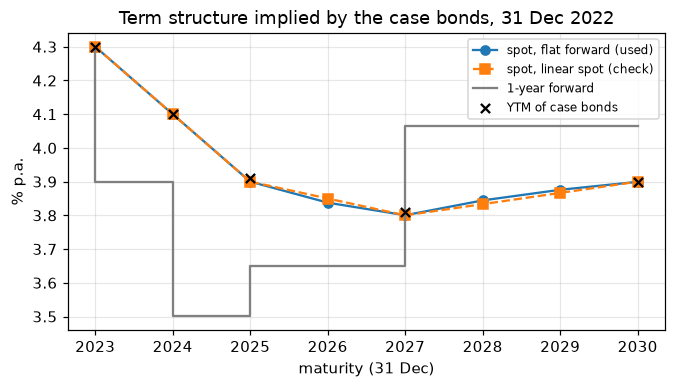

In [8]:
def pv(cf, d): return float(np.dot(cf, d[:len(cf)]))

def curve_flat_forward():
    d = np.zeros(8)
    d[0] = BONDS.loc['Alpha', 'price'] / FACE
    d[1] = BONDS.loc['Beta', 'price'] / FACE
    d[2] = (BONDS.loc['Gamma', 'price'] - 40 * (d[0] + d[1])) / 1040
    def fill(f, a, b):                                # constant forward f between year a and b
        for k in range(a, b): d[k] = d[a - 1] / (1 + f) ** (k - a + 1)
    f35 = brentq(lambda f: (fill(f, 3, 5), pv(cashflows('Delta'), d) - BONDS.loc['Delta', 'price'])[1], -0.2, 0.5)
    fill(f35, 3, 5)
    f58 = brentq(lambda f: (fill(f, 5, 8), pv(cashflows('Epsilon'), d) - BONDS.loc['Epsilon', 'price'])[1], -0.2, 0.5)
    fill(f58, 5, 8)
    return d.copy()

def curve_linear_spot():
    d = curve_flat_forward()[:3].tolist() + [0] * 5
    s = [d[t] ** (-1 / (t + 1)) - 1 for t in range(3)]
    def build(s5, s8):
        sp = s + [s[2] + (s5 - s[2]) / 2, s5] + [s5 + (s8 - s5) * k / 3 for k in (1, 2, 3)]
        return np.array([(1 + sp[t]) ** -(t + 1) for t in range(8)])
    s5 = brentq(lambda x: pv(cashflows('Delta'), build(x, x)) - BONDS.loc['Delta', 'price'], -0.2, 0.5)
    s8 = brentq(lambda x: pv(cashflows('Epsilon'), build(s5, x)) - BONDS.loc['Epsilon', 'price'], -0.2, 0.5)
    return build(s5, s8)

D = curve_flat_forward(); D_LIN = curve_linear_spot()
YEARS = np.arange(1, 9)
spot = lambda d: d ** (-1 / YEARS) - 1
fwd = lambda d: np.r_[1 / d[0], d[:-1] / d[1:]] - 1
curve = pd.DataFrame({'year': 2022 + YEARS, 'd (flat fwd)': D, 'spot (flat fwd)': spot(D), '1y forward (flat fwd)': fwd(D),
                      'd (linear spot)': D_LIN, 'spot (linear spot)': spot(D_LIN)}, index=YEARS)
save(curve, 'T04_discount_curve')
for b in BONDS.index:   # every case bond must be priced exactly by both curves
    assert abs(pv(cashflows(b), D) - BONDS.loc[b, 'price']) < 1e-6 and abs(pv(cashflows(b), D_LIN) - BONDS.loc[b, 'price']) < 1e-6
LIAB_CF = np.zeros(8); LIAB_CF[1], LIAB_CF[4] = P['LIAB'][2024], P['LIAB'][2027]
PV_L, PV_L_LIN = pv(LIAB_CF, D), pv(LIAB_CF, D_LIN)
display(curve.style.format('{:.4%}').format({'year': '{:d}', 'd (flat fwd)': '{:.6f}', 'd (linear spot)': '{:.6f}'}))
print(f'PV of liabilities: flat forward {usd(PV_L)}, linear spot {usd(PV_L_LIN)}, difference {usd(PV_L - PV_L_LIN)}')

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(curve['year'], curve['spot (flat fwd)'] * 100, 'o-', label='spot, flat forward (used)')
ax.plot(curve['year'], curve['spot (linear spot)'] * 100, 's--', label='spot, linear spot (check)')
ax.step(curve['year'], curve['1y forward (flat fwd)'] * 100, where='pre', color='grey', label='1-year forward')
ax.scatter(2022 + BONDS['maturity'], BONDS['YTM'] * 100, marker='x', color='k', zorder=3, label='YTM of case bonds')
ax.set(xlabel='maturity (31 Dec)', ylabel='% p.a.', title='Term structure implied by the case bonds, 31 Dec 2022'); ax.legend(fontsize=8)
savefig(fig, 'F01_term_structure')

**Output:** spot rates go from 4.30% (1y) to about 3.80% (5y) and 3.90% (8y). The two interpolation rules give a PV of the liabilities that differs by only about USD 50, so the choice is not material for the decision. Both curves price all five bonds exactly (assertion).

### 3.3 Duration, convexity and how good the approximation is

**What:** Macaulay duration, modified duration and convexity (at each bond's YTM), and the price change for ±100 and ±200 bp compared with exact repricing:

$$\frac{\Delta P}{P}\approx -D^{*}\,\Delta y+\tfrac12\,\text{Convexity}\,(\Delta y)^2 .$$

**Why / link:** L03. Duration tells us which bonds carry most rate risk (important for the trustees' loss concern); convexity shows when the linear approximation is not enough.

In [9]:
def risk_measures(name):
    cf, y = cashflows(name), BONDS.loc[name, 'YTM']; t = np.arange(1, len(cf) + 1)
    p = price_flat(cf, y); w = cf / (1 + y) ** t / p
    mac = (t * w).sum(); mod = mac / (1 + y); conv = (cf * t * (t + 1) / (1 + y) ** (t + 2)).sum() / p
    row = dict(Macaulay=mac, modified=mod, convexity=conv)
    for dy in (-0.02, -0.01, 0.01, 0.02):
        row[f'exact {dy * 1e4:+.0f}bp'] = price_flat(cf, y + dy) / p - 1
        row[f'dur+conv {dy * 1e4:+.0f}bp'] = -mod * dy + 0.5 * conv * dy ** 2
    return row
DUR = save(pd.DataFrame({b: risk_measures(b) for b in BONDS.index}).T, 'T05_duration_convexity')
display(DUR.style.format('{:.3f}', subset=['Macaulay', 'modified', 'convexity']).format('{:.2%}', subset=DUR.columns[3:]))

,Macaulay,modified,convexity,exact -200bp,dur+conv -200bp,exact -100bp,dur+conv -100bp,exact +100bp,dur+conv +100bp,exact +200bp,dur+conv +200bp
Alpha,1.000,0.959,1.838,1.96%,1.95%,0.97%,0.97%,-0.95%,-0.95%,-1.88%,-1.88%
Beta,2.000,1.921,5.537,3.96%,3.95%,1.95%,1.95%,-1.89%,-1.89%,-3.73%,-3.73%
Gamma,2.886,2.778,10.553,5.77%,5.77%,2.83%,2.83%,-2.73%,-2.72%,-5.35%,-5.34%
Delta,4.670,4.499,25.402,9.53%,9.51%,4.63%,4.63%,-4.37%,-4.37%,-8.51%,-8.49%
Epsilon,6.918,6.659,54.785,14.49%,14.41%,6.94%,6.93%,-6.39%,-6.38%,-12.29%,-12.22%


**Output:** Epsilon has a modified duration of about 6.7, so +200 bp costs it about 12.3%; duration + convexity gets this within 0.1 percentage point, duration alone would overstate the loss. The zero-coupon bonds have Macaulay duration equal to maturity.

### 3.4 Funding the fixed payments: exact cash-flow matching with Beta + Delta

**What:** we buy whole bonds only:
* **Delta** (matures Dec 2027): $N_D=\lceil 3{,}600{,}000/1{,}035\rceil$, so the final coupon + principal cover the 2027 payment.
* **Beta** (zero, Dec 2024): covers the 2024 payment **minus** the Delta coupons of 2023 and 2024. The 2023 coupon is held as cash at 0% for a year (conservative).
* Delta coupons in 2025–2026 and small rounding surpluses are not needed for the payments; they are moved to the growth/Epsilon part when received.

**Why:** with dedication each payment is paid by a bond maturing on that date, so the payments are safe **regardless of how rates move** and nothing has to be sold before maturity. This is the cash-flow-matching approach in L03.

In [10]:
N_D = math.ceil(P['LIAB'][2027] / (FACE * (1 + BONDS.loc['Delta', 'coupon'])))
cpn_D = BONDS.loc['Delta', 'coupon'] * FACE * N_D
N_B = math.ceil((P['LIAB'][2024] - 2 * cpn_D) / FACE)
HOLD = {'Beta': N_B, 'Delta': N_D}
COST_DED = sum(n * BONDS.loc[b, 'price'] for b, n in HOLD.items())

sched = pd.DataFrame(index=2022 + YEARS)
sched['Beta'] = [N_B * x for x in np.r_[cashflows('Beta'), np.zeros(6)]]
sched['Delta'] = [N_D * x for x in np.r_[cashflows('Delta'), np.zeros(3)]]
sched['liability'] = LIAB_CF
cash, released = 0.0, []
for yr in sched.index:                                 # 0% cash account: keep only what the next payment needs
    cash += sched.loc[yr, 'Beta'] + sched.loc[yr, 'Delta'] - sched.loc[yr, 'liability']
    need_later = 2 * cpn_D if yr == 2023 else 0.0      # 2023 coupon is kept for the 2024 payment
    rel = max(cash - need_later, 0.0); released.append(rel); cash -= rel
    sched.loc[yr, 'cash after payment'] = cash
sched['surplus released'] = released
assert (sched['cash after payment'] >= -1e-6).all()
SURPLUS = sched['surplus released'].to_numpy()
save(sched, 'T06_dedication_schedule')
display(sched.style.format('{:,.0f}'))
print(f'Beta: {N_B:,} bonds, Delta: {N_D:,} bonds; cost {usd(COST_DED)} '
      f'(PV of liabilities {usd(PV_L)}; PV of released surplus {usd(pv(SURPLUS, D))})')

,Beta,Delta,liability,cash after payment,surplus released
2023,0,"121,765",0,"121,765",0
2024,"2,157,000","121,765","2,400,000",0,530
2025,0,"121,765",0,0,"121,765"
2026,0,"121,765",0,0,"121,765"
2027,0,"3,600,765","3,600,000",0,765
2028,0,0,0,0,0
2029,0,0,0,0,0
2030,0,0,0,0,0


Beta: 2,157 bonds, Delta: 3,479 bonds; cost USD 5,420,974 (PV of liabilities USD 5,202,169; PV of released surplus USD 214,423)


**Output:** 2,157 Beta and 3,479 Delta bonds cost about USD 5.42M. This is about USD 0.22M more than the PV of the liabilities, but almost all of it comes back as the released Delta coupons of 2025–2026 (PV ≈ USD 0.21M); the small rest is the cost of keeping the 2023 coupon in cash at 0% for a year. Every year the cash account stays non-negative (assertion).

### 3.5 Rate scenarios: dedication vs. duration-matched immunization

**What:** the alternative is **immunization** with Gamma + Epsilon: same PV as the liabilities and the same (Fisher–Weil) duration. We shock the spot curve and compute the surplus at Dec 2027 (assets − liabilities, all flows moved to 2027 with the shocked curve).

Scenario sizes come from **US Treasury data 2015–2022** (12-month changes, month-end):
* parallel shift = 5th / 95th percentile of the 12-month change in the 5-year yield;
* steepener / flattener = 95th / 5th percentile of the 12-month change in the 10y − 2y slope, applied as a twist around 6 years.

**Why:** immunization only protects against small parallel shifts and needs rebalancing (L03); dedication does not depend on the shape of the curve. This test shows whether the extra simplicity of dedication costs anything.

In [11]:
def load_treasury(kind):
    df = pd.concat([pd.read_csv(RAW / 'treasury' / f'{kind}_par_yield_{y}.csv') for y in range(2015, 2023)])
    df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y')
    df = df.set_index('Date').sort_index()
    df.columns = [c.upper() for c in df.columns]
    return df / 100
UST, TIPS = load_treasury('nominal'), load_treasury('real')
ust_m = UST.resample('ME').last()
chg5 = ust_m['5 YR'].diff(12).dropna()
chg_slope = (ust_m['10 YR'] - ust_m['2 YR']).diff(12).dropna()
SHOCK = {'parallel up': chg5.quantile(0.95), 'parallel down': chg5.quantile(0.05),
         'steepener': chg_slope.quantile(0.95), 'flattener': chg_slope.quantile(0.05)}
SIGMA_DY = chg5.std()                                 # used for the 1-year VaR of the bond holdings

def shocked_curve(d, name):
    s = spot(d)
    if name.startswith('parallel'): s = s + SHOCK[name]
    elif name in ('steepener', 'flattener'): s = s + SHOCK[name] * (YEARS - 6) / 8
    return (1 + s) ** -YEARS

def fw_duration(cf, d): return float((np.arange(1, 9) * cf * d).sum() / (cf * d).sum())
cfG, cfE = np.r_[cashflows('Gamma'), np.zeros(5)], cashflows('Epsilon')
D_L, dG, dE = fw_duration(LIAB_CF, D), fw_duration(cfG, D), fw_duration(cfE, D)
wG = (dE - D_L) / (dE - dG)
nG, nE = wG * PV_L / BONDS.loc['Gamma', 'price'], (1 - wG) * PV_L / BONDS.loc['Epsilon', 'price']
A_DED = sched['Beta'].to_numpy() + sched['Delta'].to_numpy()
A_IMM = nG * cfG + nE * cfE

rows = []
for sc in ['base', 'parallel up', 'parallel down', 'steepener', 'flattener']:
    d1 = D if sc == 'base' else shocked_curve(D, sc)
    at_2027 = lambda net: float((net * d1).sum() / d1[4])   # move all net flows to Dec 2027 with the shocked curve
    rows.append({'scenario': sc, 'shock (bp)': 0 if sc == 'base' else SHOCK[sc] * 1e4,
                 'dedication: surplus 2027 (excl. released coupons)': at_2027(A_DED - LIAB_CF - SURPLUS),
                 'immunization: surplus 2027': at_2027(A_IMM - LIAB_CF)})
SCEN = pd.DataFrame(rows).set_index('scenario')
save(SCEN, 'T07_rate_scenarios')
print(f"Liability duration {D_L:.2f}y; immunization = {wG:.1%} Gamma ({nG:,.0f} bonds) + {1 - wG:.1%} Epsilon ({nE:,.0f} bonds)")
print(f"12-month change in 5y Treasury yield 2015-2022: sd {SIGMA_DY * 1e4:.0f} bp")
display(SCEN.style.format('{:,.0f}'))

Liability duration 3.72y; immunization = 79.3% Gamma (4,113 bonds) + 20.7% Epsilon (1,037 bonds)
12-month change in 5y Treasury yield 2015-2022: sd 117 bp


,shock (bp),dedication: surplus 2027 (excl. released coupons),immunization: surplus 2027
scenario,,,
base,0,"5,281",-0
parallel up,247,"9,259","2,718"
parallel down,-161,"2,964","1,042"
steepener,80,"4,887","-8,893"
flattener,-139,"5,957","16,611"


**Output:**
* Dedication stays positive in every scenario (the small positive number is the value of the 2023 coupon we keep in cash); the payments never depend on rates.
* Immunization is almost exact for parallel shifts (convexity even helps a little), but under the steepener it is short by about USD 9k. The amounts are small, but immunization also needs rebalancing as durations drift and must sell Epsilon in 2027 at an unknown price.
* Economically the two cost the same (5.42M − 0.21M released ≈ PV of the liabilities). **We keep dedication** and reject immunization as the funding method.

---

## 4. The growth goal: how much return do we need?

### 4.1 Nominal target and required return

**What:** the goal is USD 8M in Dec-2022 purchasing power at 31 Dec 2030, so in nominal dollars

$$W^{\text{target}}_{2030}=8{,}000{,}000\times(1+\pi)^{8}.$$

The money left after the bonds and the cash reserve, $R_0$, plus the released coupons (moved to 2030 with the forward curve) must reach this target. We solve for the required annual return on $R_0$ and compare with putting all of $R_0$ into Epsilon.

**Inflation assumption (2.3%):** the market's own forecast on the decision date — the Treasury breakeven rate (nominal − TIPS real yield) on 30 Dec 2022 — is about 2.3% at both 5 and 10 years. We use 3.5% as a stress case (inflation stays well above the Fed's 2% goal).

**Link:** L04 (real vs nominal returns, Fisher relation).

In [12]:
be = pd.DataFrame({'nominal': UST.loc['2022-12-30', ['5 YR', '10 YR']].values, 'real (TIPS)': TIPS.loc['2022-12-30', ['5 YR', '10 YR']].values},
                  index=['5 YR', '10 YR'])
be['breakeven'] = be['nominal'] - be['real (TIPS)']
display(be.style.format('{:.2%}'))

H = P['GOAL_YEAR'] - P['START_YEAR']
R0 = P['FUND'] - COST_DED - P['CASH']
FV_SURPLUS = float((SURPLUS * D / D[-1]).sum())       # released coupons reinvested at forward rates to 2030
def target(infl): return P['GOAL_REAL'] * (1 + infl) ** H
def required_return(infl): return brentq(lambda r: R0 * (1 + r) ** H + FV_SURPLUS + P['CASH'] - target(infl), -0.5, 1)
SAFE_2030 = R0 / D[-1] + FV_SURPLUS + P['CASH']       # everything left in Epsilon (coupons reinvested at forwards)
mand = pd.DataFrame({'base inflation': [P['INFL']], 'stress inflation': [P['INFL_STRESS']]}).T.rename(columns={0: 'inflation'})
mand['nominal target 2030'] = [target(i) for i in mand['inflation']]
mand['all-safe value 2030'] = SAFE_2030
mand['all-safe real value'] = SAFE_2030 / (1 + mand['inflation']) ** H
mand['shortfall (nominal)'] = mand['nominal target 2030'] - SAFE_2030
mand['required return on R0'] = [required_return(i) for i in mand['inflation']]
save(mand, 'T08_mandate')
print(f'R0 = {usd(R0)} (12M - bonds {usd(COST_DED)} - cash {usd(P["CASH"])}); released coupons worth {usd(FV_SURPLUS)} in 2030')
print(f"Epsilon yield {pct(BONDS.loc['Epsilon', 'YTM'])}; 8-year spot {pct(spot(D)[-1])}")
display(mand.style.format('{:,.0f}').format('{:.2%}', subset=['inflation', 'required return on R0']))

,nominal,real (TIPS),breakeven
5 YR,3.99%,1.66%,2.33%
10 YR,3.88%,1.58%,2.30%


R0 = USD 6,479,026 (12M - bonds USD 5,420,974 - cash USD 100,000); released coupons worth USD 291,191 in 2030
Epsilon yield 3.90%; 8-year spot 3.90%


,inflation,nominal target 2030,all-safe value 2030,all-safe real value,shortfall (nominal),required return on R0
base inflation,2.30%,"9,596,106","9,189,862","7,661,326","406,244",4.49%
stress inflation,3.50%,"10,534,472","9,189,862","6,978,888","1,344,610",5.76%


**Output:** with 2.3% inflation the target is about USD 9.6M nominal. Putting all of $R_0$ into Epsilon gives only about USD 9.2M — **short of the goal** (≈ USD 7.65M in real terms). The remainder needs about **4.5% a year**, i.e. more than the 3.9% safe 8-year rate, so some equity risk is necessary. Under 3.5% inflation the required return rises to about 6%.

---

## 5. Growth portfolio

### 5.1 Single-index model estimates

**What:** for each security we run the SIM regression on SPY (monthly excess returns, Jan 2016–Dec 2022):

$$r_{i,t}-r_{f,t}=\alpha_i+\beta_i\,(r_{M,t}-r_{f,t})+e_{i,t}.$$

We keep $\beta_i$, the residual standard deviation $\sigma(e_i)$ and $R^2$.

**Why / link:** L06. The SIM covariance $\Sigma_{SIM}=\beta\beta^\top\sigma_M^2+\text{diag}(\sigma^2(e_i))$ needs only $2n+1$ estimates instead of $n(n+1)/2$, which makes it much less noisy with 84 months and 12 assets.

In [13]:
xm = XR[BENCH]
rows = {}
for t in ASSETS:
    m = sm.OLS(XR[t], sm.add_constant(xm)).fit()
    rows[t] = dict(sector=SECTOR.get(t, 'ETF'), alpha_ann=12 * m.params['const'], t_alpha=m.tvalues['const'],
                   beta=m.params[BENCH], t_beta=m.tvalues[BENCH], resid_sd_ann=np.sqrt(12) * m.resid.std(ddof=2),
                   R2=m.rsquared, total_sd_ann=np.sqrt(12) * XR[t].std(), hist_mean_excess_ann=12 * XR[t].mean())
SIM = save(pd.DataFrame(rows).T, 'T09_sim_estimates')
SIG_M = np.sqrt(12) * xm.std()
display(SIM.style.format('{:.3f}', subset=['beta', 't_beta', 't_alpha', 'R2']).format('{:.2%}', subset=['alpha_ann', 'resid_sd_ann', 'total_sd_ann', 'hist_mean_excess_ann']))
print(f'SPY: annualised excess-return sd {pct(SIG_M)}; mean excess return {pct(12 * xm.mean())}')

,sector,alpha_ann,t_alpha,beta,t_beta,resid_sd_ann,R2,total_sd_ann,hist_mean_excess_ann
MSA,Industrials,9.79%,1.535,0.958,8.585,16.55%,0.473,22.66%,20.50%
KAI,Industrials,11.71%,1.378,1.240,8.346,22.04%,0.459,29.80%,25.58%
GEF,Materials,6.31%,0.699,1.053,6.667,23.42%,0.352,28.90%,18.08%
IOSP,Materials,1.11%,0.120,1.152,7.085,24.11%,0.380,30.42%,13.99%
FLO,Consumer Staples,4.10%,0.516,0.435,3.131,20.62%,0.107,21.69%,8.97%
CALM,Consumer Staples,7.05%,0.698,-0.120,-0.678,26.21%,0.006,26.12%,5.71%
IDA,Utilities,3.65%,0.581,0.580,5.273,16.30%,0.253,18.75%,10.13%
NWN,Utilities,-2.37%,-0.312,0.550,4.146,19.67%,0.173,21.50%,3.78%
CHE,Health Care,12.58%,1.687,0.610,4.675,19.35%,0.210,21.64%,19.39%
NSIT,Information Technology,8.11%,0.749,1.581,8.347,28.08%,0.459,37.97%,25.78%


SPY: annualised excess-return sd 16.28%; mean excess return 11.18%


**Output:** betas range from about −0.1 (CALM, egg prices have little to do with the market) and 0.4–0.6 (FLO, utilities, CHE) to 1.6 (NSIT). The two ETFs have $R^2$ of 0.78 and 0.93; single stocks only 0.01–0.47, so most of their risk is firm-specific and can be diversified away. No alpha is significant at 5% (largest $t$ = 1.7 for CHE), so we do not rely on historical alphas.

### 5.2 Inputs for the optimizer: expected returns and two covariance matrices

**What:**
* **Expected excess return** (one year): $E(r_i)-r_f=\beta_i\times\text{ERP}$ with ERP = 5% (CAPM, L06). The risk-free rate for the one-year CAL is the Alpha yield, $r_f$ = 4.30%.
* **Covariance:** sample covariance vs. SIM covariance, both from monthly excess returns × 12.

**Why:** historical average returns over 7 years are very noisy (standard error ≈ σ/√7 ≈ 8–10% a year for a single stock) and would reward the names that did best in the past. CAPM expected returns are a neutral starting point that uses only risk information.

**ERP = 5%:** the historical premium of the S&P 500 over US T-bonds in 1928–2022 is 5.1% (geometric) and 6.6% (arithmetic), and Damodaran's implied ERP at the start of 2023 is 5.94% (all from the saved Damodaran workbook, see notebook B). We take the lower end, and we add it to the 1-year rate (4.30%) rather than the 10-year rate (3.88%), which is also conservative. We test 3–6% in Section 5.8.

In [14]:
RF1 = BONDS.loc['Alpha', 'YTM']
beta, sig_e = SIM['beta'].astype(float).to_numpy(), SIM['resid_sd_ann'].astype(float).to_numpy()
MU_X = beta * P['ERP']                                # expected excess return (CAPM)
COV_S = 12 * XR[ASSETS].cov().to_numpy()
COV_SIM = np.outer(beta, beta) * SIG_M ** 2 + np.diag(sig_e ** 2)
corr = lambda c: c / np.sqrt(np.outer(np.diag(c), np.diag(c)))
off = ~np.eye(len(ASSETS), dtype=bool)
print(f'average pairwise correlation: sample {corr(COV_S)[off].mean():.3f}, SIM {corr(COV_SIM)[off].mean():.3f}')
print(f'condition number: sample {np.linalg.cond(COV_S):,.0f}, SIM {np.linalg.cond(COV_SIM):,.0f}')
display(pd.DataFrame({'E(r) - rf (CAPM)': MU_X, 'E(r)': RF1 + MU_X, 'sd sample': np.sqrt(np.diag(COV_S)), 'sd SIM': np.sqrt(np.diag(COV_SIM))},
                     index=ASSETS).T.style.format('{:.2%}'))

average pairwise correlation: sample 0.373, SIM 0.307
condition number: sample 283, SIM 92


,MSA,KAI,GEF,IOSP,FLO,CALM,IDA,NWN,CHE,NSIT,XMLV,RWL
E(r) - rf (CAPM),4.79%,6.20%,5.26%,5.76%,2.18%,-0.60%,2.90%,2.75%,3.05%,7.90%,4.01%,5.00%
E(r),9.09%,10.50%,9.56%,10.06%,6.48%,3.70%,7.20%,7.05%,7.35%,12.20%,8.31%,9.30%
sd sample,22.66%,29.80%,28.90%,30.42%,21.69%,26.12%,18.75%,21.50%,21.64%,37.97%,14.77%,16.92%
sd SIM,22.74%,29.89%,29.02%,30.54%,21.81%,26.28%,18.83%,21.61%,21.75%,38.09%,14.79%,16.93%


**Output:** the SIM keeps (almost exactly) each asset's total variance but sets all residual correlations to zero; the sample matrix keeps them (e.g. the two utilities and the two ETFs also move together beyond the market). The average correlation is 0.37 (sample) vs. 0.31 (SIM), and the sample matrix is about three times worse conditioned — this is what lets optimizers produce extreme weights from small estimation errors.

### 5.3 Three candidate portfolios

**What:** all are long-only and maximise the Sharpe ratio $\big(E(r_P)-r_f\big)/\sigma_P$ (L05):

| Portfolio | Expected returns | Covariance | Weight limits |
|:--|:--|:--|:--|
| **Eta (rejected)** | historical means 2016–2022 | sample | none (only $w\ge 0$) |
| Constrained – sample | CAPM | sample | stock 1–8%, ETF 1–35%, sector ≤ 15% |
| **Constrained – SIM (recommended)** | CAPM | SIM | same |

**Why the limits:** they keep every candidate in the portfolio (≥ 8 stocks, 6 sectors), stop the optimizer from betting on estimation error, and keep single-stock positions small relative to their trading volume.

In [15]:
SECT_IDX = {s: [i for i, t in enumerate(ASSETS) if SECTOR.get(t) == s] for s in set(SECTOR.values())}
def max_sharpe(mu_x, cov, constrained=True):
    n = len(mu_x)
    if constrained:
        bounds = [(P['W_MIN'], P['W_STOCK_MAX'] if t in STOCKS else P['W_ETF_MAX']) for t in ASSETS]
        cons = [{'type': 'eq', 'fun': lambda w: w.sum() - 1}] + \
               [{'type': 'ineq', 'fun': lambda w, ix=ix: P['W_SECTOR_MAX'] - w[ix].sum()} for ix in SECT_IDX.values()]
    else:
        bounds, cons = [(0, 1)] * n, [{'type': 'eq', 'fun': lambda w: w.sum() - 1}]
    obj = lambda w: -(w @ mu_x) / np.sqrt(w @ cov @ w)
    best = None
    for k in range(20):                                # several starting points; keep the best
        w0 = np.random.default_rng(k).dirichlet(np.ones(n))
        res = minimize(obj, w0, method='SLSQP', bounds=bounds, constraints=cons, options={'maxiter': 1000, 'ftol': 1e-12})
        if res.success and (best is None or res.fun < best.fun): best = res
    w = np.clip(best.x, 0, None); return w / w.sum()

MU_HIST = SIM['hist_mean_excess_ann'].astype(float).to_numpy()
W = pd.DataFrame({'Eta (hist. mean, sample, no limits)': max_sharpe(MU_HIST, COV_S, False),
                  'Constrained - sample cov': max_sharpe(MU_X, COV_S),
                  'Constrained - SIM cov (recommended)': max_sharpe(MU_X, COV_SIM)}, index=ASSETS)
def stats(w, mu_x=MU_X, cov=COV_SIM):
    m, s = w @ mu_x, np.sqrt(w @ cov @ w)
    return {'E(r) - rf (CAPM)': m, 'sd (SIM cov)': s, 'Sharpe (CAPM, SIM)': m / s, 'beta': w @ beta,
            'hist. mean excess': w @ MU_HIST, 'sd (sample cov)': np.sqrt(w @ COV_S @ w),
            'largest weight': w.max(), 'holdings > 0.5%': int((w > 0.005).sum())}
W_STATS = pd.DataFrame({c: stats(W[c].to_numpy()) for c in W})
W_SPY = pd.Series({'E(r) - rf (CAPM)': P['ERP'], 'sd (SIM cov)': SIG_M, 'Sharpe (CAPM, SIM)': P['ERP'] / SIG_M, 'beta': 1.0,
                   'hist. mean excess': 12 * xm.mean(), 'sd (sample cov)': SIG_M, 'largest weight': 1.0, 'holdings > 0.5%': 1}, name='SPY')
W_STATS = W_STATS.join(W_SPY)
save(pd.concat([W, W_STATS.iloc[:, :3]]), 'T10_weights_compare')
display(W.style.format('{:.1%}'))
display(W_STATS.style.format('{:.3f}'))

,"Eta (hist. mean, sample, no limits)",Constrained - sample cov,Constrained - SIM cov (recommended)
MSA,26.0%,4.2%,6.2%
KAI,22.3%,8.0%,4.3%
GEF,4.0%,3.4%,3.3%
IOSP,0.0%,1.0%,3.4%
FLO,0.0%,2.0%,2.3%
CALM,9.9%,1.0%,1.0%
IDA,0.0%,1.0%,4.4%
NWN,0.0%,1.0%,2.9%
CHE,36.7%,5.4%,3.2%
NSIT,1.1%,2.9%,3.3%


,"Eta (hist. mean, sample, no limits)",Constrained - sample cov,Constrained - SIM cov (recommended),SPY
E(r) - rf (CAPM),0.040,0.046,0.045,0.050
sd (SIM cov),0.164,0.154,0.152,0.163
"Sharpe (CAPM, SIM)",0.243,0.297,0.299,0.307
beta,0.797,0.916,0.905,1.000
hist. mean excess,0.197,0.127,0.122,0.112
sd (sample cov),0.166,0.158,0.157,0.163
largest weight,0.367,0.350,0.350,1.000
holdings > 0.5%,6.000,12.000,12.000,1.000


**Output:**
* **Eta** holds only 6 names and puts 85% into CHE, MSA and KAI, the best performers of 2016–2022. Its *historical* Sharpe ratio is about 1.2 (19.7% excess return / 16.6% risk) against 0.78 for our portfolio, but this is the in-sample bias from L05/L08: past means are estimated badly and the optimizer simply picks past winners. Judged with CAPM expected returns, Eta is the worst of the three (Sharpe 0.24). **Rejected.**
* Both constrained portfolios hold all 12 securities. Their CAPM Sharpe ratios (≈ 0.30) are just below SPY's (0.31) — under CAPM no asset beats the market, and the small gap is the firm-specific risk we keep by holding 10 single stocks, as the brief requires.
* With the sample covariance, 7 of 12 weights end up on a bound (1%, 8% or 35%); with the SIM only 2. The sample version reacts to historical correlations between pairs of stocks, which are noisy.

### 5.4 Which covariance estimate should we trust? An out-of-sample check

**What:** we estimate both covariance matrices on **2016–2019 only**, build the constrained portfolio, and compare the volatility each matrix *predicted* with the volatility *realised* in 2020–2022.

**Why:** the brief asks us to justify the risk estimate. A good estimate should predict future risk of the portfolio it chooses; this test uses no information after 2022.

In [16]:
def fit_inputs(window):
    x = XR.loc[window]; xmw = x[BENCH]
    b = np.array([sm.OLS(x[t], sm.add_constant(xmw)).fit().params[BENCH] for t in ASSETS])
    e = np.array([np.sqrt(12) * sm.OLS(x[t], sm.add_constant(xmw)).fit().resid.std(ddof=2) for t in ASSETS])
    sm2 = 12 * xmw.var()
    return b, 12 * x[ASSETS].cov().to_numpy(), np.outer(b, b) * sm2 + np.diag(e ** 2)

b1, cs1, csim1 = fit_inputs(slice('2016-01', '2019-12'))
b2, cs2, csim2 = fit_inputs(slice('2020-01', '2022-12'))
realised = XR.loc['2020-01':'2022-12', ASSETS]
rows = {}
for lab, cov1 in [('sample cov', cs1), ('SIM cov', csim1)]:
    w = max_sharpe(b1 * P['ERP'], cov1)
    rows[lab] = {'predicted sd (2016-19)': np.sqrt(w @ cov1 @ w), 'realised sd (2020-22)': np.sqrt(12) * (realised @ w).std(),
                 'beta 2016-19': w @ b1, 'beta 2020-22': w @ b2}
oos = pd.DataFrame(rows).T
oos['realised / predicted'] = oos['realised sd (2020-22)'] / oos['predicted sd (2016-19)']
display(oos.style.format('{:.3f}'))

,predicted sd (2016-19),realised sd (2020-22),beta 2016-19,beta 2020-22,realised / predicted
sample cov,0.120,0.203,0.973,0.904,1.698
SIM cov,0.109,0.200,0.906,0.889,1.836


**Output:** neither estimate saw 2020–2022 coming — both underpredict realised risk by 70–85%, because the Covid crash and the 2022 rate shock were a new regime. The SIM portfolio's realised volatility was slightly lower (20.0% vs 20.3%), while its prediction was a little further off. So the test does **not** show that SIM forecasts risk better; it shows that the two give portfolios with almost the same realised risk. We keep SIM because it gives the same risk with weights that are less driven by noisy pairwise correlations (previous step and next step), and we do **not** trust either number as a risk limit — this is why the loss limits in 5.6 use a stress scenario and not only $\sigma_P$.

### 5.5 Robustness to the estimation window

**What:** we re-estimate the recommended portfolio on 2016–2019 and on 2020–2022 and compare the weights with the full-window weights.

**Why:** if a small change in the window moved the weights a lot, the portfolio would mainly reflect noise and generate high turnover at each rebalancing.

In [17]:
W_SUB = pd.DataFrame({'full 2016-22': W['Constrained - SIM cov (recommended)'],
                      '2016-19 only': max_sharpe(b1 * P['ERP'], csim1), '2020-22 only': max_sharpe(b2 * P['ERP'], csim2)}, index=ASSETS)
W_SUB.loc['one-way turnover vs full'] = [0.5 * (W_SUB.iloc[:12, k] - W_SUB.iloc[:12, 0]).abs().sum() for k in range(3)]
save(W_SUB, 'T11_window_robustness')
display(W_SUB.style.format('{:.1%}'))

,full 2016-22,2016-19 only,2020-22 only
MSA,6.2%,6.1%,5.6%
KAI,4.3%,3.6%,5.3%
GEF,3.3%,3.1%,4.2%
IOSP,3.4%,3.5%,3.2%
FLO,2.3%,1.4%,4.2%
CALM,1.0%,1.2%,1.0%
IDA,4.4%,3.1%,4.5%
NWN,2.9%,2.3%,2.9%
CHE,3.2%,4.3%,2.4%
NSIT,3.3%,1.9%,6.0%


**Output:** single-stock weights move by at most about 3 percentage points and XMLV by about 5; the one-way turnover against the full-window portfolio is only 5–7%. RWL stays at its 35% cap in all windows. The policy is therefore not very sensitive to the window choice.

### 5.6 How much of the remainder goes into equities?

**What:** the remainder $R_0$ is split between the growth portfolio $P$ (share $y$) and Epsilon (share $1-y$).

1. **Utility optimum (L04/L05):** $y^*=\dfrac{E(r_P)-r_f}{A\,\sigma_P^2}$ with $A=4$.
2. **Loss limit 1 – VaR:** 1-year 95% normal VaR ≤ 10% of the fund.
3. **Loss limit 2 – stress:** equity −40% **at the same time as** the 95th-percentile 12-month rise in the 5-year yield (from 3.5, ≈ +250 bp), loss ≤ 15% of the fund.

Losses are measured on the fund **net of the two fixed payments** (market value of all assets − PV of the payments), in % of USD 12M. The final share is the smallest of the three.

**Why this reading of "uneasy with losses of about 15%":**
* The trustees did not say "never lose 15%", so we treat 15% as the most they could accept in a severe but plausible year (stress) and use a stricter 10% for a normal bad year (1-in-20 VaR).
* −40% is roughly the 2008 fall of the S&P 500 (−37% total return); combining it with a 2022-type rate rise is deliberately harsh.
* Net of the payments, because when yields rise the dedicated bonds fall in price but the payments they fund fall in value by almost the same amount — nothing is lost for the foundation. We still show the **gross** market-value loss, since that is the number the trustees would see on a statement.

In [18]:
w_rec = W['Constrained - SIM cov (recommended)'].to_numpy()
MU_P, SD_P, BETA_P = w_rec @ MU_X, np.sqrt(w_rec @ COV_SIM @ w_rec), w_rec @ beta
ust_d5 = ust_m['5 YR'].diff().loc['2016-01':'2022-12'].to_numpy()
RHO = np.corrcoef(R[BENCH].to_numpy(), ust_d5)[0, 1]  # equity vs. yield changes (monthly)
RATE_UP = SHOCK['parallel up']

def bond_value(hold, dy=0.0, d=D):
    dd = (1 + spot(d) + dy) ** -YEARS
    return sum(n * pv(np.r_[cashflows(b), np.zeros(8 - len(cashflows(b)))], dd) for b, n in hold.items())

def liab_value(dy=0.0, d=D):
    return pv(LIAB_CF, (1 + spot(d) + dy) ** -YEARS)

def fund_risk(y):
    # One-year risk of the fund NET of the fixed payments (surplus = assets - PV of payments), in % of USD 12M
    G, E = y * R0, (1 - y) * R0
    hold = {**HOLD, 'Epsilon': E / BONDS.loc['Epsilon', 'price']}
    B, L = bond_value(hold), liab_value()
    dv_net = (bond_value(hold, 1e-4) - liab_value(1e-4) - bond_value(hold, -1e-4) + liab_value(-1e-4)) / 2e-4  # USD per unit of dy
    mu = (G * (RF1 + MU_P) + (B - L) * RF1) / P['FUND']                      # bonds and payments both accrue at ~ the 1-year rate
    s_g, s_b = G * SD_P / P['FUND'], abs(dv_net) * SIGMA_DY / P['FUND']
    sd = np.sqrt(s_g ** 2 + s_b ** 2 - 2 * RHO * s_g * s_b)                   # yields up = bond prices down
    var95 = -(mu - P['Z95'] * sd)
    d_net = bond_value(hold, RATE_UP) - B - (liab_value(RATE_UP) - L)
    stress = -(G * P['EQ_STRESS'] + d_net) / P['FUND']
    gross = -(G * P['EQ_STRESS'] + bond_value(hold, RATE_UP) - B) / P['FUND']  # what a market-value statement would show
    return dict(y=y, equity_share_total=G / P['FUND'], exp_return=mu, sd=sd, VaR95=var95, stress_loss=stress,
                gross_MTM_stress_loss=gross)

Y_UTIL = lambda A: MU_P / (A * SD_P ** 2)
Y_VAR = brentq(lambda y: fund_risk(y)['VaR95'] - P['VAR_LIMIT'], 0, 1) if fund_risk(1)['VaR95'] > P['VAR_LIMIT'] else 1.0
Y_STRESS = brentq(lambda y: fund_risk(y)['stress_loss'] - P['STRESS_LIMIT'], 0, 1) if fund_risk(1)['stress_loss'] > P['STRESS_LIMIT'] else 1.0
lim = {'utility y* (A=4)': Y_UTIL(P['A']), 'VaR limit': Y_VAR, 'stress limit': Y_STRESS}
Y_FINAL = math.floor(100 * min(min(lim.values()), 1.0)) / 100
BINDING = min(lim, key=lim.get)
RISK = save(pd.DataFrame({k: fund_risk(min(v, 1)) for k, v in {**lim, 'chosen': Y_FINAL}.items()}).T, 'T12_risk_limits')
print(f'Growth portfolio: E(r) = {pct(RF1 + MU_P)}, sd = {pct(SD_P)}, beta = {BETA_P:.2f}; corr(SPY, d5y) = {RHO:.2f}; stress yield rise = {RATE_UP * 1e4:.0f} bp')
display(RISK.style.format('{:.2%}'))
display(Markdown(f'**Chosen share of the remainder in equities: y = {Y_FINAL:.0%}** (binding: {BINDING}) '
                 f'→ {usd(Y_FINAL * R0)} in the growth portfolio = {Y_FINAL * R0 / P["FUND"]:.1%} of the fund.'))

Growth portfolio: E(r) = 8.83%, sd = 15.16%, beta = 0.91; corr(SPY, d5y) = 0.00; stress yield rise = 247 bp


,y,equity_share_total,exp_return,sd,VaR95,stress_loss,gross_MTM_stress_loss
utility y* (A=4),49.23%,26.58%,3.60%,4.58%,3.94%,14.84%,18.45%
VaR limit,100.00%,53.99%,4.84%,8.18%,8.62%,21.72%,25.33%
stress limit,50.42%,27.22%,3.63%,4.65%,4.01%,15.00%,18.61%
chosen,49.00%,26.46%,3.60%,4.57%,3.92%,14.81%,18.42%


**Chosen share of the remainder in equities: y = 49%** (binding: utility y* (A=4)) → USD 3,174,723 in the growth portfolio = 26.5% of the fund.

**Output:** the table shows each rule's maximum equity share and the fund's risk at that share. The chosen $y$ is the smallest of the three, rounded down to a whole percent; the binding rule is printed above. The last column shows that a statement could still show a larger gross loss in the stress scenario, mostly from the dedicated bonds — we will explain this to the trustees rather than sell the bonds.

### 5.7 Goal probability for 2030

**What:** we project the fund to Dec 2030: the growth portfolio follows a lognormal process with annual mean $s_8+\beta_P\cdot\text{ERP}$ ($s_8$ = 8-year spot rate) and volatility $\sigma_P$; Epsilon, the released coupons and the cash are known in nominal terms. Then

$$\Pr\!\left(\frac{W_{2030}}{(1+\pi)^8}\ge 8\text{M}\right)=1-\Phi\!\left(\frac{\ln(\text{need}/G_0)-8m}{s\sqrt8}\right),$$

where "need" is the amount the growth portfolio must reach. We also simulate 20,000 paths to show the distribution.

**Why:** the goal is long-term and real, while the risk limits are one-year; this step shows whether the chosen $y$ gives a reasonable chance of the goal.

Analytical: P(goal) = 67.0%, median real wealth USD 8,743,084, 5th pct USD 6,514,754
Simulation: P(goal) = 67.2%


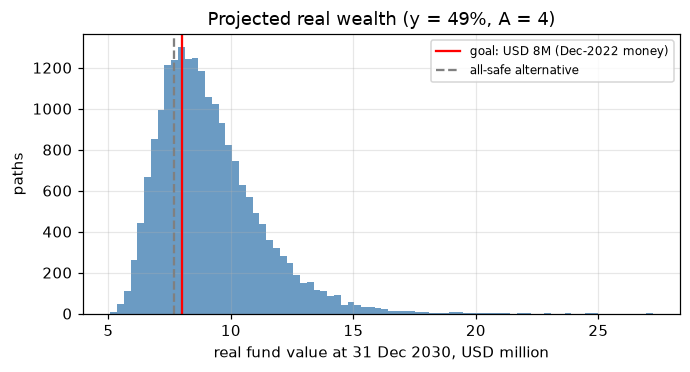

In [19]:
S8 = spot(D)[-1]
def lognorm_params(mu, sd):
    s2 = np.log(1 + sd ** 2 / (1 + mu) ** 2); return np.log(1 + mu) - s2 / 2, np.sqrt(s2)

def goal(y, erp=P['ERP'], infl=P['INFL'], sd=None):
    sd = SD_P if sd is None else sd
    G0 = y * R0 * (1 - TC_AVG); safe = (1 - y) * R0 / D[-1] + FV_SURPLUS + P['CASH']
    need = target(infl) - safe
    m, s = lognorm_params(S8 + BETA_P * erp, sd)
    prob = 1.0 if need <= 0 else 1 - norm.cdf((np.log(need / G0) - H * m) / (s * np.sqrt(H)))
    med = (safe + G0 * np.exp(H * m)) / (1 + infl) ** H
    p05 = (safe + G0 * np.exp(H * m + norm.ppf(0.05) * s * np.sqrt(H))) / (1 + infl) ** H
    return dict(prob_goal=prob, median_real_2030=med, p05_real_2030=p05)

tc = np.array([P['TC_STOCK'] if t in STOCKS else P['TC_ETF'] for t in ASSETS]); TC_AVG = w_rec @ tc
GOAL = goal(Y_FINAL)
m, s = lognorm_params(S8 + BETA_P * P['ERP'], SD_P)
rng = np.random.default_rng(P['SEED'])
G_T = Y_FINAL * R0 * (1 - TC_AVG) * np.exp(rng.normal(m, s, (20_000, H)).sum(axis=1))
W_REAL = (G_T + (1 - Y_FINAL) * R0 / D[-1] + FV_SURPLUS + P['CASH']) / (1 + P['INFL']) ** H
print(f"Analytical: P(goal) = {GOAL['prob_goal']:.1%}, median real wealth {usd(GOAL['median_real_2030'])}, 5th pct {usd(GOAL['p05_real_2030'])}")
print(f'Simulation: P(goal) = {(W_REAL >= P["GOAL_REAL"]).mean():.1%}')
fig, ax = plt.subplots(figsize=(7, 3.3))
ax.hist(W_REAL / 1e6, bins=80, color='steelblue', alpha=0.8)
ax.axvline(P['GOAL_REAL'] / 1e6, color='red', label='goal: USD 8M (Dec-2022 money)')
ax.axvline(SAFE_2030 / (1 + P['INFL']) ** H / 1e6, color='grey', ls='--', label='all-safe alternative')
ax.set(xlabel='real fund value at 31 Dec 2030, USD million', ylabel='paths', title=f'Projected real wealth (y = {Y_FINAL:.0%}, A = {P["A"]})'); ax.legend(fontsize=8)
savefig(fig, 'F02_goal_distribution')

**Output:** the analytical and simulated probabilities agree (about 67%). In a bad case (5th percentile) the real value is about USD 6.5M, i.e. roughly USD 1.1M below the all-safe alternative — this is the price of a two-in-three chance of reaching the goal, compared with no chance if everything stays in safe bonds.

### 5.8 Sensitivity: risk aversion, ERP and inflation

**What:** we vary one assumption at a time and report $y$, which rule binds and the goal probability. We also solve for the **reversal thresholds**: the ERP and the inflation rate at which the goal probability with our frozen allocation falls below 50%.

**Why:** the brief asks which assumptions would change the decision. These thresholds are part of the evaluation rule in Section 7.

In [20]:
rows = []
for A in P['A_GRID']:
    yA = math.floor(100 * min(Y_UTIL(A), Y_VAR, Y_STRESS, 1)) / 100
    rows.append({'case': f'A = {A}', 'y': yA, 'binding': min({'utility': Y_UTIL(A), 'VaR': Y_VAR, 'stress': Y_STRESS}.items(), key=lambda kv: kv[1])[0],
                 **{k: v for k, v in fund_risk(yA).items() if k in ('VaR95', 'stress_loss')}, **goal(yA)})
for erp in [0.03, 0.04, 0.05, 0.06]:
    rows.append({'case': f'ERP = {erp:.0%} (y frozen)', 'y': Y_FINAL, 'binding': '-', **goal(Y_FINAL, erp=erp)})
for infl in [0.02, 0.023, 0.03, 0.035]:
    rows.append({'case': f'inflation = {infl:.1%} (y frozen)', 'y': Y_FINAL, 'binding': '-', **goal(Y_FINAL, infl=infl)})
rows.append({'case': 'sample-cov risk of same weights', 'y': Y_FINAL, 'binding': '-', **goal(Y_FINAL, sd=np.sqrt(w_rec @ COV_S @ w_rec))})
SENS = save(pd.DataFrame(rows).set_index('case'), 'T14_sensitivity')
ERP_STAR = brentq(lambda e: goal(Y_FINAL, erp=e)['prob_goal'] - 0.5, -0.05, 0.15)
INFL_STAR = brentq(lambda i: goal(Y_FINAL, infl=i)['prob_goal'] - 0.5, -0.02, 0.10)
display(SENS.style.format('{:.1%}', subset=['y', 'VaR95', 'stress_loss', 'prob_goal']).format('{:,.0f}', subset=['median_real_2030', 'p05_real_2030']).format(na_rep='-'))
print(f'Reversal thresholds: goal probability < 50% if ERP < {pct(ERP_STAR)} or inflation > {pct(INFL_STAR)} (other inputs unchanged)')

,y,binding,VaR95,stress_loss,prob_goal,median_real_2030,p05_real_2030
case,,,,,,,
A = 2,0.500000,stress,0.039861,0.149430,0.671530,8765160.221248,6491354.391247
A = 3,0.500000,stress,0.039861,0.149430,0.671530,8765160.221248,6491354.391247
A = 4,0.490000,utility,0.039248,0.148075,0.669946,8743083.533355,6514753.819955
A = 5,0.390000,utility,0.034396,0.134527,0.649609,8522316.654426,6748748.107026
A = 6,0.320000,utility,0.032647,0.125043,0.627824,8367779.839176,6912544.107975
A = 8,0.240000,utility,0.032651,0.114205,0.587639,8191166.336033,7099739.537632
ERP = 3% (y frozen),0.490000,-,-,-,0.535588,8143115.921833,6177605.142123
ERP = 4% (y frozen),0.490000,-,-,-,0.604055,8434114.592384,6340720.804595
ERP = 5% (y frozen),0.490000,-,-,-,0.669946,8743083.533355,6514753.819955


Reversal thresholds: goal probability < 50% if ERP < 2.49% or inflation > 3.44% (other inputs unchanged)


**Output:**
* With $A = 4$ the utility optimum (49%) is just below the stress limit (50%), so the two rules give almost the same answer. For $A \le 3$ the stress limit binds; for $A \ge 5$ risk aversion lowers $y$ and the goal probability falls to 59–65%.
* The VaR limit never binds (it allows 100%).
* The goal probability reacts most to **inflation**: at about 3.4% it falls below 50%. For the ERP the threshold is about 2.5%. These two levels are our review triggers in Section 7.

### 5.9 Full allocation of the USD 12 million

**What:** dollar amounts, whole bonds and whole shares at the 30 Dec 2022 closing prices, trading costs, and the cash that is left.

**Why:** the brief asks for an initial dollar allocation that adds up exactly; rounding and costs go to the cash reserve.

,type,sector,units,price,cost,total,% of fund,% of growth sleeve,purpose
item,,,,,,,,,
Beta,case bond,-,"2,157",922.78,0,"1,990,436",16.59%,,payments (Beta + Delta)
Delta,case bond,-,"3,479",986.07,0,"3,430,538",28.59%,,payments (Beta + Delta)
Epsilon,case bond,-,"3,175","1,040.71",0,"3,304,254",27.54%,,"Epsilon (safe, to 2030)"
MSA,stock,Industrials,"1,359",144.19,196,"196,150",1.63%,6.2%,growth
KAI,stock,Industrials,767,177.63,136,"136,378",1.14%,4.3%,growth
GEF,stock,Materials,"1,574",67.06,106,"105,658",0.88%,3.3%,growth
IOSP,stock,Materials,"1,042",102.86,107,"107,287",0.89%,3.4%,growth
FLO,stock,Consumer Staples,"2,487",28.74,71,"71,548",0.60%,2.3%,growth
CALM,stock,Consumer Staples,582,54.45,32,"31,722",0.26%,1.0%,growth


,USD
purpose,
"Epsilon (safe, to 2030)","3,304,254"
cash reserve,"100,900"
growth,"3,173,872"
payments (Beta + Delta),"5,420,974"


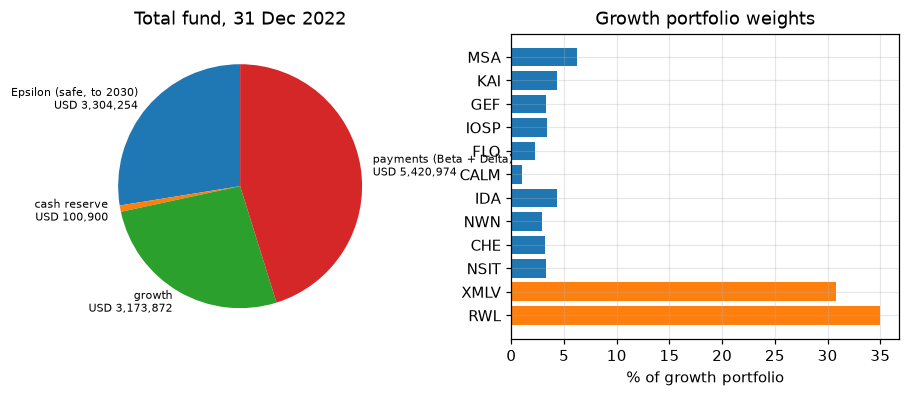

In [21]:
N_E = math.floor((1 - Y_FINAL) * R0 / BONDS.loc['Epsilon', 'price'])
G_BUDGET = Y_FINAL * R0
px30 = quality['close_30Dec2022']
rows = []
for b, n in {**HOLD, 'Epsilon': N_E}.items():
    rows.append(dict(item=b, type='case bond', sector='-', units=n, price=BONDS.loc[b, 'price'], cost=0.0, total=n * BONDS.loc[b, 'price']))
for t, w in zip(ASSETS, w_rec):
    c = P['TC_STOCK'] if t in STOCKS else P['TC_ETF']
    n = math.floor(w * G_BUDGET / (px30[t] * (1 + c)))
    rows.append(dict(item=t, type='stock' if t in STOCKS else 'ETF', sector=SECTOR.get(t, 'diversified'),
                     units=n, price=px30[t], cost=n * px30[t] * c, total=n * px30[t] * (1 + c)))
ALLOC = pd.DataFrame(rows).set_index('item')
ALLOC.loc['Cash', ['type', 'sector', 'units', 'price', 'cost', 'total']] = ['cash', '-', np.nan, np.nan, 0.0, P['FUND'] - ALLOC['total'].sum()]
ALLOC['% of fund'] = ALLOC['total'] / P['FUND']
ALLOC['% of growth sleeve'] = np.where(ALLOC['type'].isin(['stock', 'ETF']), ALLOC['total'] / ALLOC.loc[ALLOC['type'].isin(['stock', 'ETF']), 'total'].sum(), np.nan)
ALLOC['purpose'] = ALLOC['type'].map({'case bond': 'payments (Beta + Delta)', 'stock': 'growth', 'ETF': 'growth', 'cash': 'cash reserve'})
ALLOC.loc['Epsilon', 'purpose'] = 'Epsilon (safe, to 2030)'
save(ALLOC, 'T13_allocation_12M')
assert abs(ALLOC['total'].sum() - P['FUND']) < 0.01 and ALLOC.loc['Cash', 'total'] >= P['CASH']
summary = ALLOC.groupby('purpose')['total'].sum()
display(ALLOC.style.format({'units': '{:,.0f}', 'price': '{:,.2f}', 'cost': '{:,.0f}', 'total': '{:,.0f}', '% of fund': '{:.2%}', '% of growth sleeve': '{:.1%}'}, na_rep=''))
display(summary.to_frame('USD').style.format('{:,.0f}'))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].pie(summary, labels=[f'{k}\n{usd(v)}' for k, v in summary.items()], startangle=90, textprops={'fontsize': 7})
ax[0].set_title('Total fund, 31 Dec 2022')
g = ALLOC[ALLOC['type'].isin(['stock', 'ETF'])]
ax[1].barh(g.index[::-1], g['% of growth sleeve'][::-1] * 100, color=['tab:orange' if t in ETFS else 'tab:blue' for t in g.index[::-1]])
ax[1].set(xlabel='% of growth portfolio', title='Growth portfolio weights')
savefig(fig, 'F03_allocation')

**Output:** the allocation adds up to exactly USD 12,000,000. The cash line is the USD 100k reserve plus the rounding left over from whole bonds and whole shares.

---

## 6. Preliminary factor check (in-sample, 2016–2022)

**What:** we regress the monthly excess return of the recommended growth portfolio (frozen weights, rebalanced monthly in this test), and of two stocks with unusual betas (CALM, IDA), on

* CAPM: $\text{Mkt-RF}$
* Fama–French 3: $+\ \text{SMB} + \text{HML}$
* Carhart 4: $+\ \text{MOM}$

with Newey–West (HAC, 3 lags) standard errors.

**Why / link:** L07. CAPM alpha can simply be a reward for size or value exposure. This tells us what the portfolio really is (e.g. a small/mid-cap value tilt) before we evaluate it. It is only a preliminary in-sample check; the real test is 2023–2025.

In [22]:
port_x = (XR[ASSETS] * w_rec).sum(axis=1)
targets = {'Growth portfolio': port_x, 'CALM': XR['CALM'], 'IDA': XR['IDA']}
models = {'CAPM': ['Mkt-RF'], 'FF3': ['Mkt-RF', 'SMB', 'HML'], 'Carhart': ['Mkt-RF', 'SMB', 'HML', 'Mom']}
rows = []
for name, y_ in targets.items():
    for mname, f in models.items():
        res = sm.OLS(y_, sm.add_constant(FFe[f])).fit(cov_type='HAC', cov_kwds={'maxlags': 3})
        row = {'series': name, 'model': mname, 'alpha_ann': 12 * res.params['const'], 't_alpha': res.tvalues['const'], 'adj_R2': res.rsquared_adj}
        row.update({f'b_{k}': res.params[k] for k in f}); row.update({f't_{k}': res.tvalues[k] for k in f})
        rows.append(row)
FAC = save(pd.DataFrame(rows).set_index(['series', 'model']), 'T15_factor_check')
cols = ['alpha_ann', 't_alpha', 'b_Mkt-RF', 'b_SMB', 'b_HML', 'b_Mom', 't_SMB', 't_HML', 'adj_R2']
display(FAC[cols].style.format('{:.3f}', na_rep='').format('{:.2%}', subset=['alpha_ann']))

**Output:**
* The growth portfolio has a market beta of about 0.85 and a clear **value** tilt (HML ≈ 0.23, $t$ ≈ 7), while its size loading is close to zero — the mid-cap names are balanced by RWL's large caps. Momentum plays no role.
* Adding SMB and HML raises adjusted $R^2$ from 0.87 to 0.91 and makes the alpha's $t$-statistic rise to about 1.4, still not significant.
* CALM has no market exposure at all; IDA has a market beta of about 0.5–0.6 and a negative size loading.
* No alpha is significant, consistent with semi-strong efficiency (L08) and with our choice not to use historical alphas. In the 2023–2025 evaluation we will report FF3/Carhart alphas next to CAPM alpha so that a value effect is not mistaken for skill.

---

## 7. Frozen evaluation and rebalancing rule (2023–2025)

**Rule (fixed today, not changed after seeing 2023–2025 data):**

1. **Holdings:** bonds held to maturity; Beta pays Dec 2024, Delta pays Dec 2027, Epsilon held to 2030. Released Delta coupons (Dec 2025, Dec 2026) are added to the growth portfolio at the frozen weights.
2. **Growth portfolio rebalancing:** at the last trading day of Dec 2023 and Dec 2024, back to the frozen weights if any weight has drifted by more than **3 percentage points**; trading costs 10 bp (stocks) / 3 bp (ETFs) on the traded amount. No change of securities or weights in between.
3. **Comparator:** SPY, buy-and-hold, total return (Adj Close), same start value net of 3 bp cost.
4. **Metrics:** cumulative and annualised return, volatility, Sharpe ratio (French RF), maximum drawdown, tracking error and information ratio vs. SPY, CAPM alpha/beta vs. SPY and FF3/Carhart alpha; real value of the total fund vs. the USD 8M path.
5. **Review triggers** (would make us revise the policy, not the past evaluation): a breach of the 15% stress-loss limit in market value; an inflation outlook above **the threshold from Section 5.8**; or an ERP view below **the threshold from Section 5.8**.

The code below defines the evaluation but only runs it when `RUN_EVALUATION = True`. For this initial decision record it stays `False` — we have not looked at 2023–2025 returns.

In [23]:
RUN_EVALUATION = False

def evaluate(w, start_value):
    r = R_TOT.loc[P['EVAL_START']:P['EVAL_END'], ASSETS + [BENCH]]
    rf = FF.loc[P['EVAL_START']:P['EVAL_END'], 'RF']
    hold = pd.Series(w, ASSETS) * start_value * (1 - pd.Series(tc, ASSETS))
    spy = start_value * (1 - P['TC_ETF']); path, costs = [], 0.0
    for per, row in r.iterrows():
        hold = hold * (1 + row[ASSETS]); spy *= 1 + row[BENCH]
        if per.month == 12 and per.year in (2023, 2024):
            cur = hold / hold.sum()
            if (cur - w).abs().max() > P['DRIFT_BAND']:
                trade = (pd.Series(w, ASSETS) * hold.sum() - hold).abs()
                c = (trade * tc).sum(); costs += c; hold = pd.Series(w, ASSETS) * (hold.sum() - c)
        path.append({'month': per, 'growth': hold.sum(), 'SPY': spy})
    path = pd.DataFrame(path).set_index('month'); ret = path.pct_change()
    ret.iloc[0] = path.iloc[0] / [start_value, start_value] - 1
    ex = ret.sub(rf, axis=0); act = ret['growth'] - ret['SPY']
    out = {}
    for c in ['growth', 'SPY']:
        out[c] = {'cumulative': path[c].iloc[-1] / start_value - 1, 'annualised': (path[c].iloc[-1] / start_value) ** (12 / len(ret)) - 1,
                  'volatility': np.sqrt(12) * ret[c].std(), 'Sharpe': np.sqrt(12) * ex[c].mean() / ex[c].std(),
                  'max drawdown': (path[c] / path[c].cummax() - 1).min()}
    capm = sm.OLS(ex['growth'], sm.add_constant(ex['SPY'])).fit()
    out['growth'].update({'tracking error': np.sqrt(12) * act.std(), 'information ratio': np.sqrt(12) * act.mean() / act.std(),
                          'CAPM alpha (ann.)': 12 * capm.params['const'], 'CAPM beta': capm.params['SPY'], 'rebalancing costs': costs})
    return path, pd.DataFrame(out)

if RUN_EVALUATION:
    EVAL_PATH, EVAL = evaluate(w_rec, G_BUDGET)
    display(EVAL)
else:
    print('Evaluation not run (initial decision record). Rule frozen above; set RUN_EVALUATION = True for the final report.')

Evaluation not run (initial decision record). Rule frozen above; set RUN_EVALUATION = True for the final report.


**Output:** nothing is evaluated yet; the function is part of the frozen policy.

---

## 8. Freeze the policy

**What:** we write all decisions, assumptions and input-file hashes to `frozen_policy.json`, check the mandate rules once more, and list the output files.

**Why:** in the final submission we must show that the evaluated policy is the one decided on 22 October; the JSON (with the date and hashes) is the reference for that.

In [24]:
checks = {
    'allocation sums to USD 12,000,000': abs(ALLOC['total'].sum() - P['FUND']) < 0.01,
    'no borrowing / no short positions': (ALLOC['total'] >= 0).all() and ALLOC.loc['Cash', 'total'] >= 0,
    '8-12 stocks held, >= 4 sectors': 8 <= (ALLOC['type'] == 'stock').sum() <= 12 and ALLOC.loc[ALLOC['type'] == 'stock', 'sector'].nunique() >= 4,
    'exactly 2 ETFs held': (ALLOC['type'] == 'ETF').sum() == 2,
    'weight limits respected': (w_rec <= np.where(np.isin(ASSETS, STOCKS), P['W_STOCK_MAX'], P['W_ETF_MAX']) + 1e-6).all(),
    'sector limit respected': all(w_rec[ix].sum() <= P['W_SECTOR_MAX'] + 1e-6 for ix in SECT_IDX.values()),
    '2024 and 2027 payments fully covered by bonds': (sched['cash after payment'] >= -1e-6).all(),
    'stress loss within 15%': fund_risk(Y_FINAL)['stress_loss'] <= P['STRESS_LIMIT'] + 1e-9,
    'VaR within 10%': fund_risk(Y_FINAL)['VaR95'] <= P['VAR_LIMIT'] + 1e-9,
    'decision data end in Dec 2022': R.index.max() == pd.Period('2022-12', 'M'),
}
display(pd.Series(checks, name='passed').to_frame())
assert all(checks.values())

policy = {
    'decision_date': '2022-12-31', 'frozen_on': '2026-10-22', 'tag': P['TAG'],
    'assumptions': {k: v for k, v in P.items() if k not in ('TAG',)},
    'estimation_window': [P['EST_START'], P['EST_END'], int(len(R))],
    'bonds': {'Beta': N_B, 'Delta': N_D, 'Epsilon': N_E, 'funding_method': 'exact cash-flow matching (Beta + Delta)'},
    'growth_weights': {t: round(float(w), 6) for t, w in zip(ASSETS, w_rec)},
    'growth_method': 'max Sharpe, CAPM expected returns (beta x ERP), single-index covariance, long-only with limits',
    'equity_share_of_remainder': Y_FINAL, 'binding_rule': BINDING,
    'allocation_usd': {k: round(float(v), 2) for k, v in ALLOC['total'].items()},
    'benchmark': 'SPY buy-and-hold total return',
    'rebalancing': f"December 2023 and 2024 to frozen weights if any drift > {P['DRIFT_BAND']:.0%}",
    'review_thresholds': {'ERP_below': round(ERP_STAR, 4), 'inflation_above': round(INFL_STAR, 4), 'stress_loss_above': P['STRESS_LIMIT']},
    'key_results': {'PV_liabilities': round(PV_L, 2), 'bond_cost': round(COST_DED, 2), 'R0': round(R0, 2),
                    'growth_E_r': round(float(RF1 + MU_P), 4), 'growth_sd': round(float(SD_P), 4), 'growth_beta': round(float(BETA_P), 3),
                    'prob_goal': round(GOAL['prob_goal'], 4), 'stress_loss': round(fund_risk(Y_FINAL)['stress_loss'], 4),
                    'VaR95': round(fund_risk(Y_FINAL)['VaR95'], 4)},
    'input_hashes': dict(zip(ok['file'], ok['sha256'])),
}
(OUT / 'frozen_policy.json').write_text(json.dumps(policy, indent=2, default=str))
print('Saved outputs:')
for f in sorted(OUT.iterdir()): print('  ', f.relative_to(ROOT))

,passed
"allocation sums to USD 12,000,000",True
no borrowing / no short positions,True
"8-12 stocks held, >= 4 sectors",True
exactly 2 ETFs held,True
weight limits respected,True
sector limit respected,True
2024 and 2027 payments fully covered by bonds,True
stress loss within 15%,True
VaR within 10%,True
decision data end in Dec 2022,True


Saved outputs:
   outputs/original_22Oct/F01_term_structure.png
   outputs/original_22Oct/F02_goal_distribution.png
   outputs/original_22Oct/F03_allocation.png
   outputs/original_22Oct/T01_data_quality.csv
   outputs/original_22Oct/T02_eligibility.csv
   outputs/original_22Oct/T03_bond_yields.csv
   outputs/original_22Oct/T04_discount_curve.csv
   outputs/original_22Oct/T05_duration_convexity.csv
   outputs/original_22Oct/T06_dedication_schedule.csv
   outputs/original_22Oct/T07_rate_scenarios.csv
   outputs/original_22Oct/T08_mandate.csv
   outputs/original_22Oct/T09_sim_estimates.csv
   outputs/original_22Oct/T10_weights_compare.csv
   outputs/original_22Oct/T11_window_robustness.csv
   outputs/original_22Oct/T12_risk_limits.csv
   outputs/original_22Oct/T13_allocation_12M.csv
   outputs/original_22Oct/T14_sensitivity.csv
   outputs/original_22Oct/T15_factor_check.csv
   outputs/original_22Oct/frozen_policy.json


**Output:** all checks pass and the frozen policy is saved. These numbers are the ones reported in the Initial Decision Record (`docs/`).